In [24]:
%pip install awkward vector uproot

import argparse
import sys

import awkward as ak
import numpy as np
import uproot
import vector

vector.register_awkward()

In [2]:
%pip install fsspec-xrootd

import uproot

# Define the XRootD redirector URL
file_path = "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_t-channel_top_4f_InclusiveDecays_TuneCP5_13TeV-powheg-madspin-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/100000/69C05408-C030-0849-8DD7-AF43B44161D9.root"

# Open the file and inspect the tree
with uproot.open(file_path) as f:
    print(f.keys())  # Usually contains 'Events', 'Runs', 'LuminosityBlocks'
    events_tree = f["Events"]
    print(events_tree.show())  # Displays available physics objects/branches


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 92.6 MB/s eta 0:00:00
['tag;1', 'Events;1', 'LuminosityBlocks;1', 'Runs;1', 'MetaData;1', 'ParameterSets;1']
name                 | typename                 | interpretation                
---------------------+--------------------------+-------------------------------
run                  | uint32_t                 | AsDtype('>u4')
luminosityBlock      | uint32_t                 | AsDtype('>u4')
event                | uint64_t                 | AsDtype('>u8')
HTXS_Higgs_pt        | float                    | AsDtype('>f4')
HTXS_Higgs_y         | float                    | AsDtype('>f4')
HTXS_stage1_1_cat... | int32_t                  | AsDtype('>i4')
HTXS_stage1_1_cat... | int32_t                  | AsDtype('>i4')
HTXS_stage1_1_fin... | int32_t                  | AsDtype('>i4')
HTXS_stage1_1_fin... | int32_t                  | AsDtype('>i4')
HTXS_stage1_2_cat... | int32_t                  | AsDtype('>i4')
HTXS_stage1_2_cat... | i

In [26]:
tree_name = "Events"
output_file = "Top-test.root"

In [27]:
import os

print(os.listdir("/content"))

['.config', 'hackathon-hsf.ipynb', 'Higgs.root', 'sample_data']


In [28]:
import os

print("Files available in Colab:")
print(os.listdir("/content"))

Files available in Colab:
['.config', 'hackathon-hsf.ipynb', 'Higgs.root', 'sample_data']


In [30]:
import uproot

file = uproot.open("/content/Higgs.root")

print("Contents of the ROOT file:")
print(file.keys())

Contents of the ROOT file:
['Events;1']


In [31]:
tree = file["Events"]

print(tree)

<ROOT::RNTuple 'Events' (29 fields) at 0x7fb49c123ed0>


In [32]:
print(tree.keys())

['Electron_charge', 'Electron_eta', 'Electron_mass', 'Electron_mvaFall17V2Iso_WP90', 'Electron_phi', 'Electron_pt', 'Jet_btagDeepFlavB', 'Jet_eta', 'Jet_jetId', 'Jet_mass', 'Jet_phi', 'Jet_pt', 'Jet_puId', 'Muon_charge', 'Muon_eta', 'Muon_mass', 'Muon_pfRelIso04_all', 'Muon_phi', 'Muon_pt', 'Muon_tightId', 'PuppiMET_phi', 'PuppiMET_pt', 'dphill', 'mjj', 'mll', 'mth', 'mtw2', 'nJet', 'ptll']


In [33]:
print("Number of events:", tree.num_entries)

Number of events: 2000


In [34]:
data = tree.arrays(
    ["Electron_pt", "Muon_pt", "Jet_pt", "mll", "mjj", "ptll"],
    library="ak"
)

print(data.fields)

['Electron_pt', 'Jet_pt', 'Muon_pt', 'mjj', 'mll', 'ptll']


In [35]:
print(data[0])

{Electron_pt: [], Jet_pt: [53.3], Muon_pt: [43.4], mjj: 0, mll: -999, ...}


In [37]:
import uproot

file = uproot.open("/content/Higgs.root")
tree = file["Events"]

print("Events:", tree.num_entries)
print("Variables:", tree.keys())

Events: 2000
Variables: ['Electron_charge', 'Electron_eta', 'Electron_mass', 'Electron_mvaFall17V2Iso_WP90', 'Electron_phi', 'Electron_pt', 'Jet_btagDeepFlavB', 'Jet_eta', 'Jet_jetId', 'Jet_mass', 'Jet_phi', 'Jet_pt', 'Jet_puId', 'Muon_charge', 'Muon_eta', 'Muon_mass', 'Muon_pfRelIso04_all', 'Muon_phi', 'Muon_pt', 'Muon_tightId', 'PuppiMET_phi', 'PuppiMET_pt', 'dphill', 'mjj', 'mll', 'mth', 'mtw2', 'nJet', 'ptll']


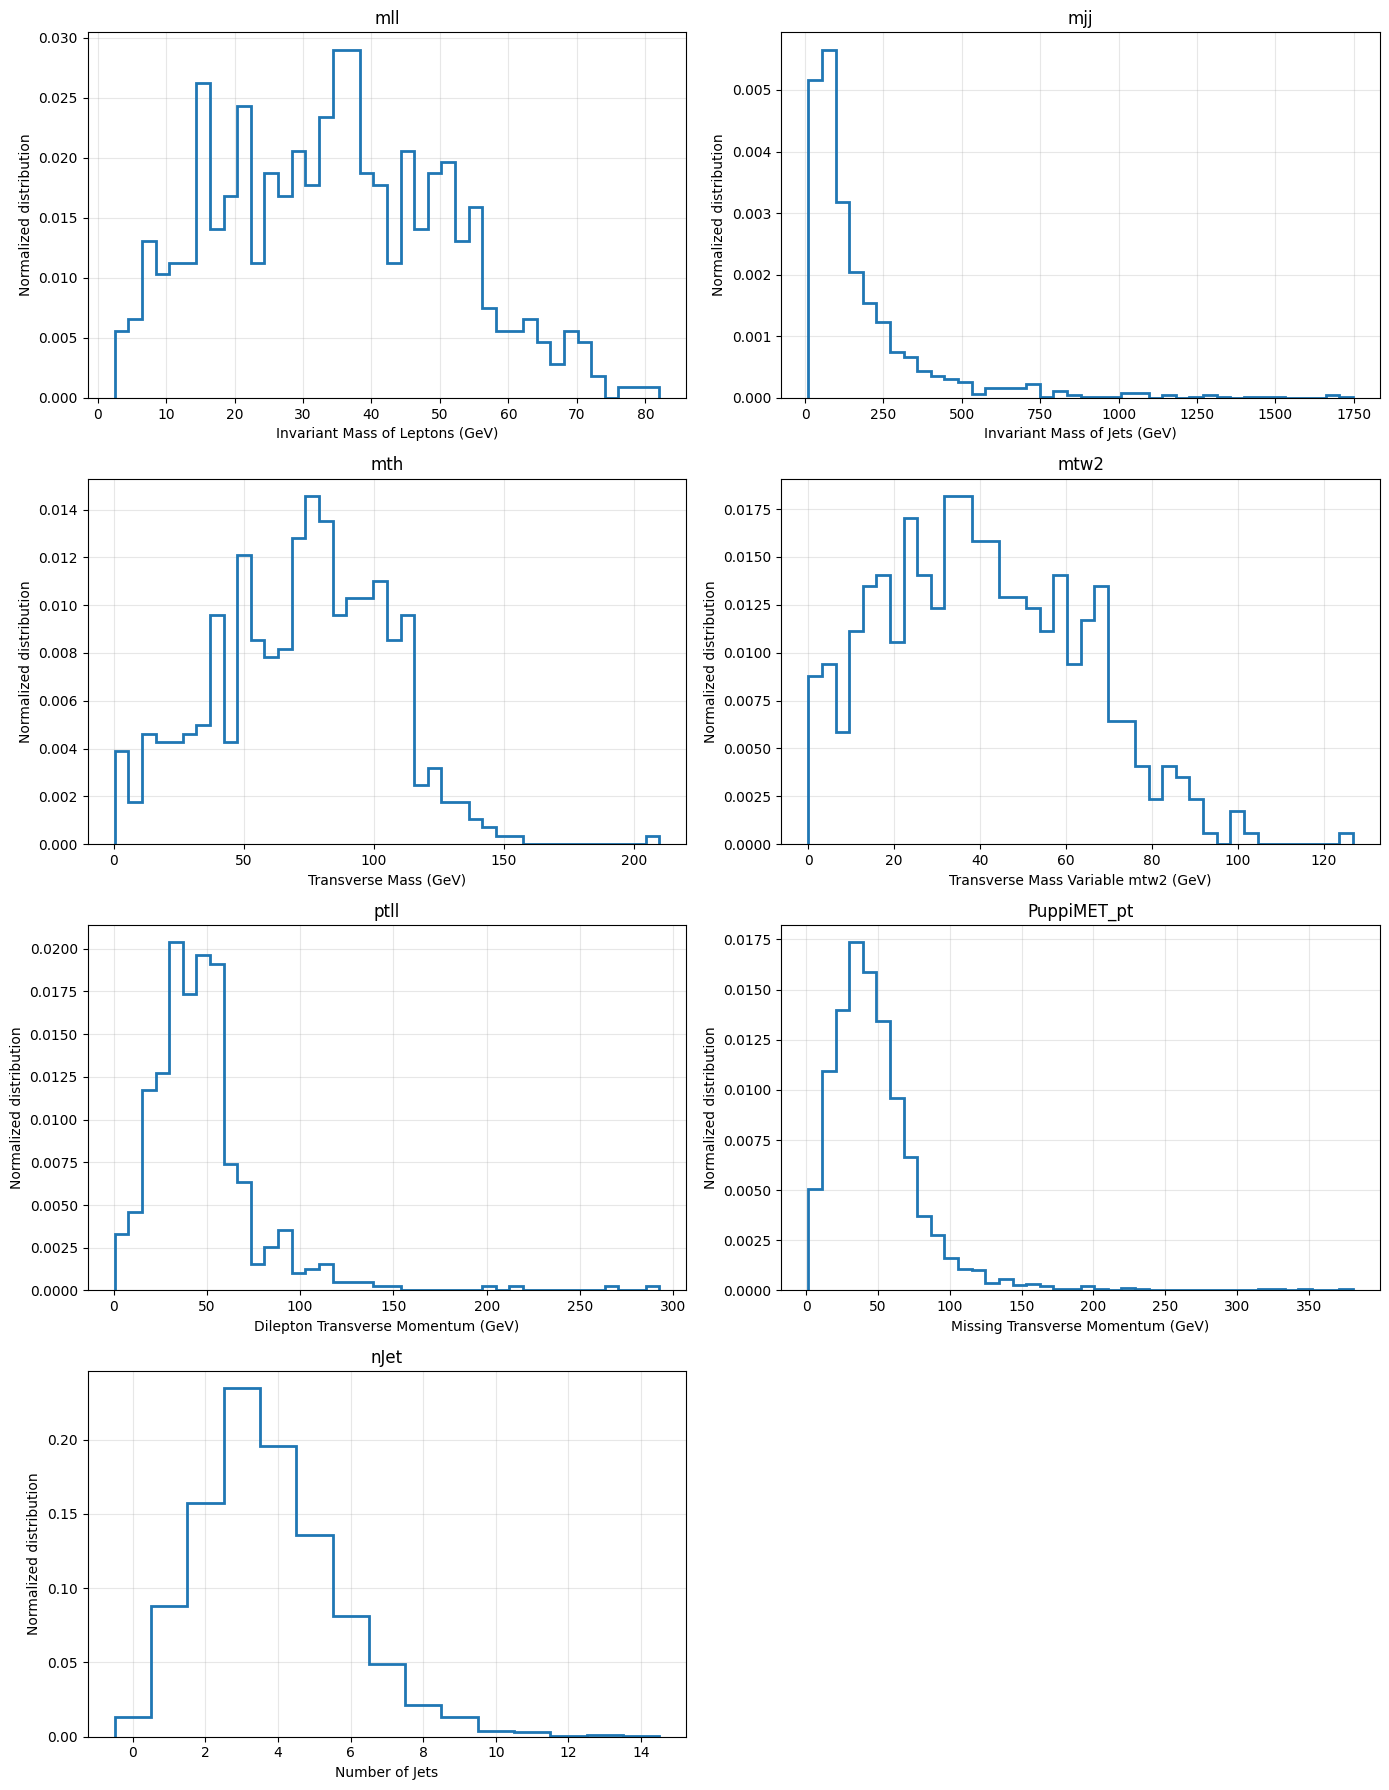

In [40]:
import numpy as np
import matplotlib.pyplot as plt

# Variables available in your ROOT file
variables = {
    "mll": "Invariant Mass of Leptons (GeV)",
    "mjj": "Invariant Mass of Jets (GeV)",
    "mth": "Transverse Mass (GeV)",
    "mtw2": "Transverse Mass Variable mtw2 (GeV)",
    "ptll": "Dilepton Transverse Momentum (GeV)",
    "PuppiMET_pt": "Missing Transverse Momentum (GeV)",
    "nJet": "Number of Jets"
}

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, (name, label) in enumerate(variables.items()):
    values = tree[name].array(library="np")
    values = np.asarray(values, dtype=float)

    # Remove invalid values for plotting
    if name == "nJet":
        values = values[np.isfinite(values) & (values >= 0)]
    else:
        values = values[np.isfinite(values) & (values > 0)]

    # Use integer bins for the number of jets
    if name == "nJet":
        bins = np.arange(-0.5, np.max(values) + 1.5, 1)
        axes[i].hist(values, bins=bins, density=True,
                     histtype="step", linewidth=2)
    else:
        axes[i].hist(values, bins=40, density=True,
                     histtype="step", linewidth=2)

    axes[i].set_title(name)
    axes[i].set_xlabel(label)
    axes[i].set_ylabel("Normalized distribution")
    axes[i].grid(alpha=0.3)

# Remove the unused eighth subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


Variable: mll
Higgs.root: 0 values outside the displayed range
WW-train.root: 2558 values outside the displayed range

Variable: mjj
Higgs.root: 22 values outside the displayed range
WW-train.root: 10108 values outside the displayed range

Variable: mth
Higgs.root: 0 values outside the displayed range
WW-train.root: 2558 values outside the displayed range

Variable: mtw2
Higgs.root: 0 values outside the displayed range
WW-train.root: 2558 values outside the displayed range

Variable: ptll
Higgs.root: 3 values outside the displayed range
WW-train.root: 2555 values outside the displayed range

Variable: PuppiMET_pt
Higgs.root: 7 values outside the displayed range
WW-train.root: 10123 values outside the displayed range

Variable: nJet


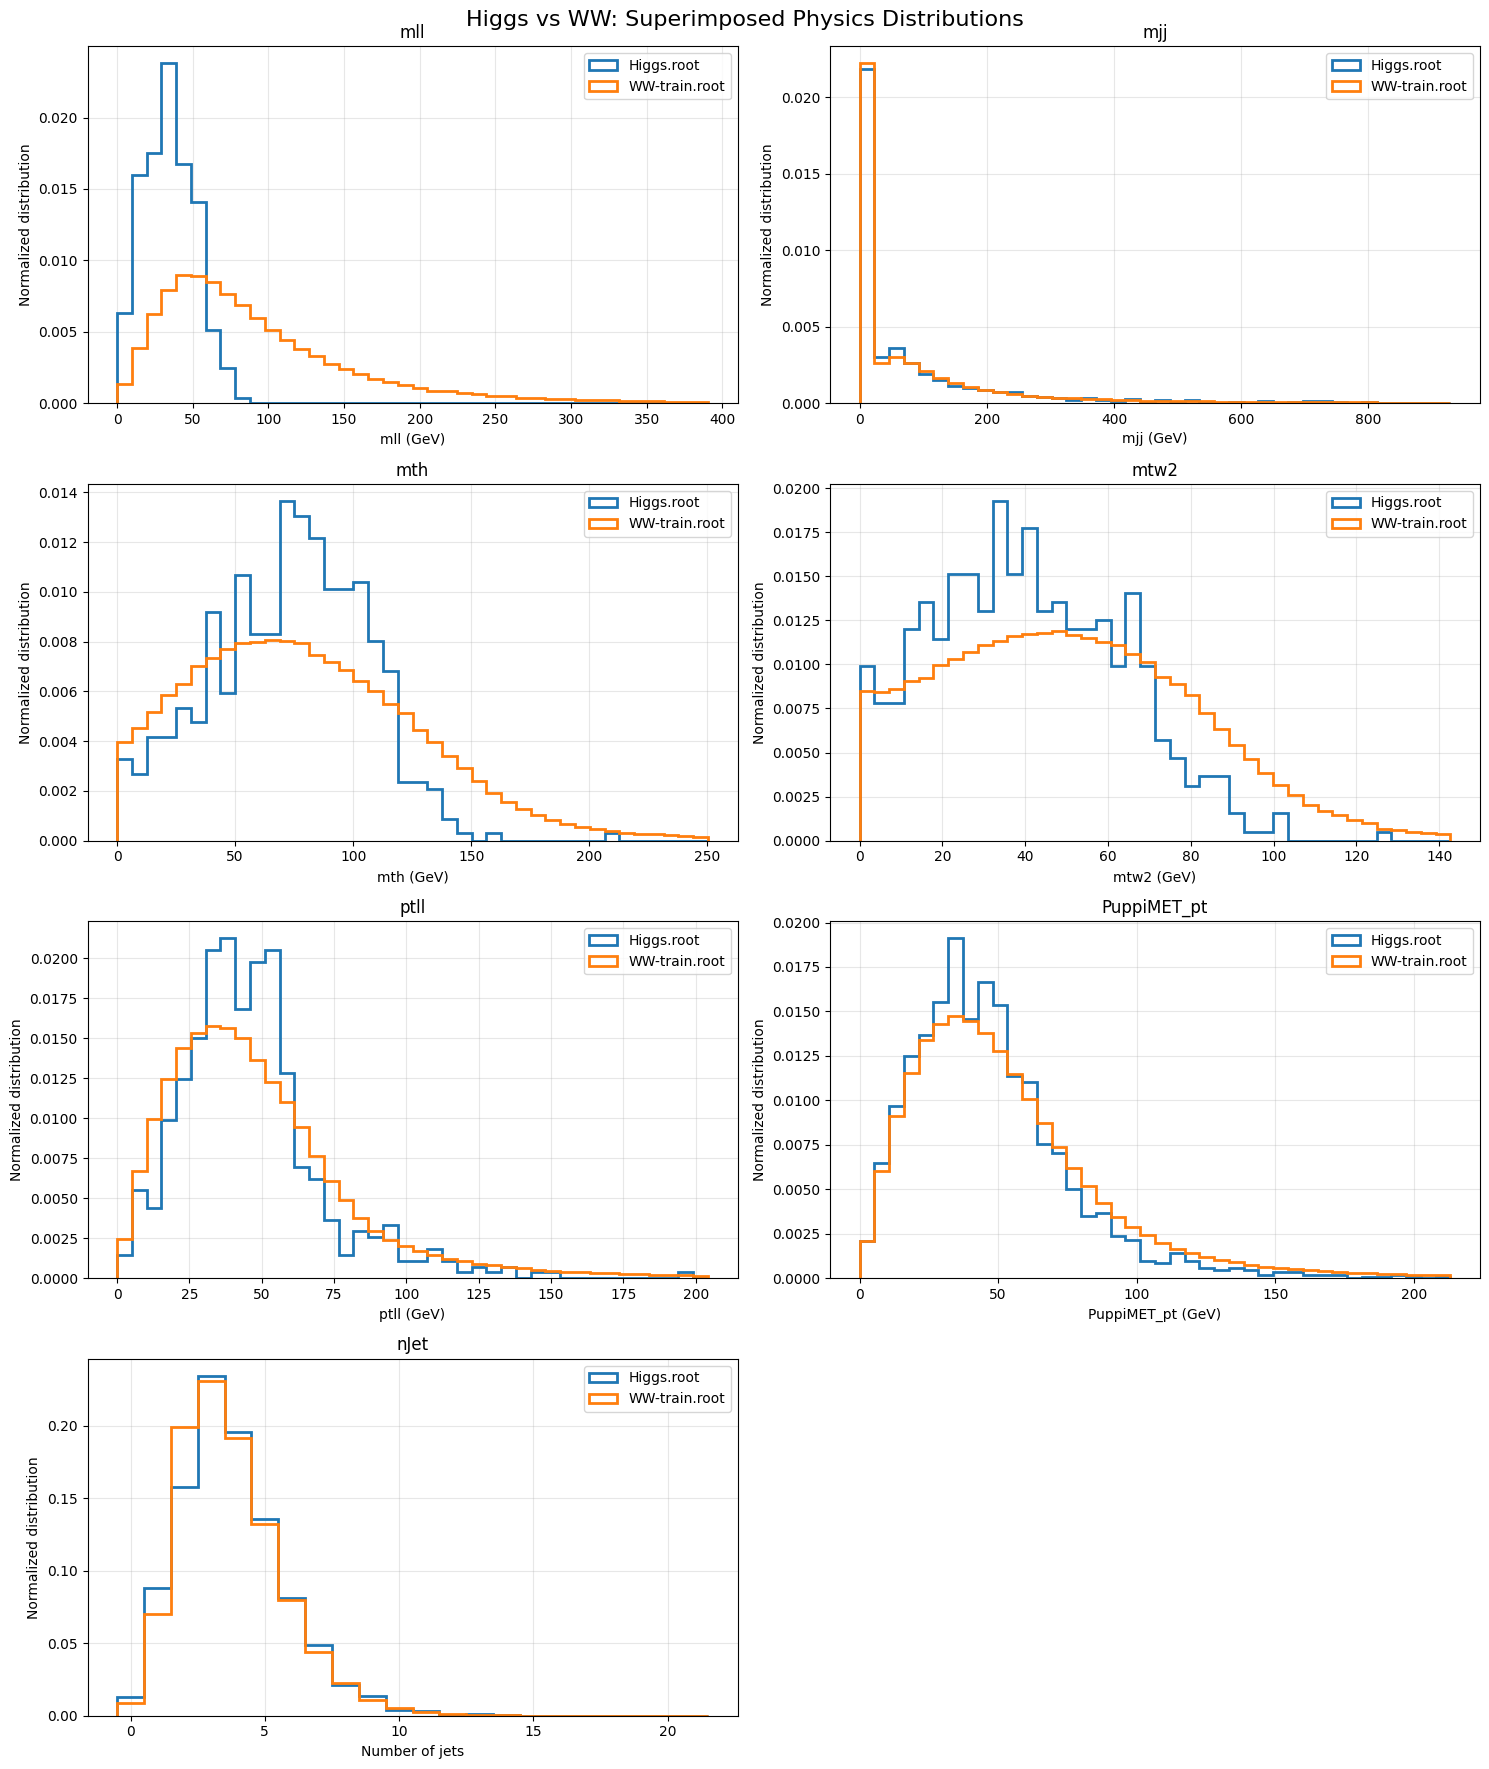


Saved superimposed_plots.png


In [48]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
import os

# Our two ROOT files
samples = {
    "Higgs.root": "/content/Higgs.root",
    "WW-train.root": "/content/WW-train.root"
}

# Variables to compare
variables = [
    "mll", "mjj", "mth", "mtw2",
    "ptll", "PuppiMET_pt", "nJet"
]

# Find a tree containing the requested variable
def read_variable(filepath, variable):
    with uproot.open(filepath) as root_file:
        for key in root_file.keys():
            obj = root_file[key]

            if (hasattr(obj, "num_entries")
                    and variable in obj.keys()):
                values = obj[variable].array(library="np")
                values = np.asarray(values, dtype=float)

                # Remove invalid values and negative placeholders
                values = values[np.isfinite(values)]
                values = values[values >= 0]

                return values

    raise ValueError(
        f"Variable '{variable}' not found in {filepath}"
    )

# Prepare a figure containing seven comparisons
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for i, variable in enumerate(variables):
    ax = axes[i]
    data = {}

    # Read the variable from both files
    for sample_name, filepath in samples.items():
        data[sample_name] = read_variable(filepath, variable)

    combined = np.concatenate(list(data.values()))

    if variable == "nJet":
        # Integer bins for jet counts
        max_value = int(np.max(combined))
        bins = np.arange(-0.5, max_value + 1.5, 1)
        upper = max_value
    else:
        # Zoom to the 99th percentile to make the
        # main distributions easier to compare
        upper = np.percentile(combined, 99)
        upper = max(upper, 0.001)
        bins = np.linspace(0, upper, 41)

    print(f"\nVariable: {variable}")

    for sample_name, values in data.items():
        if variable == "nJet":
            visible = values
        else:
            visible = values[values <= upper]
            outside = np.sum(values > upper)

            print(
                f"{sample_name}: {outside} values "
                f"outside the displayed range"
            )

        if len(visible) > 0:
            ax.hist(
                visible,
                bins=bins,
                density=True,
                histtype="step",
                linewidth=2,
                label=sample_name
            )

    ax.set_title(variable)
    ax.set_xlabel(variable + " (GeV)" if variable != "nJet" else "Number of jets")
    ax.set_ylabel("Normalized distribution")
    ax.grid(alpha=0.3)
    ax.legend()

# Remove the unused eighth panel
fig.delaxes(axes[-1])

fig.suptitle(
    "Higgs vs WW: Superimposed Physics Distributions",
    fontsize=16
)
plt.tight_layout()

# Save your plots
plt.savefig(
    "/content/superimposed_plots.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nSaved superimposed_plots.png")


Variable: mll
Higgs: 0 values outside the displayed range
WW: 3029 values outside the displayed range
Top: 494 values outside the displayed range

Variable: mjj
Higgs: 10 values outside the displayed range
WW: 4991 values outside the displayed range
Top: 82589 values outside the displayed range

Variable: mth
Higgs: 0 values outside the displayed range
WW: 2460 values outside the displayed range
Top: 1063 values outside the displayed range

Variable: mtw2
Higgs: 0 values outside the displayed range
WW: 2429 values outside the displayed range
Top: 1094 values outside the displayed range

Variable: ptll
Higgs: 3 values outside the displayed range
WW: 2520 values outside the displayed range
Top: 1000 values outside the displayed range

Variable: PuppiMET_pt
Higgs: 14 values outside the displayed range
WW: 19458 values outside the displayed range
Top: 68118 values outside the displayed range

Variable: nJet


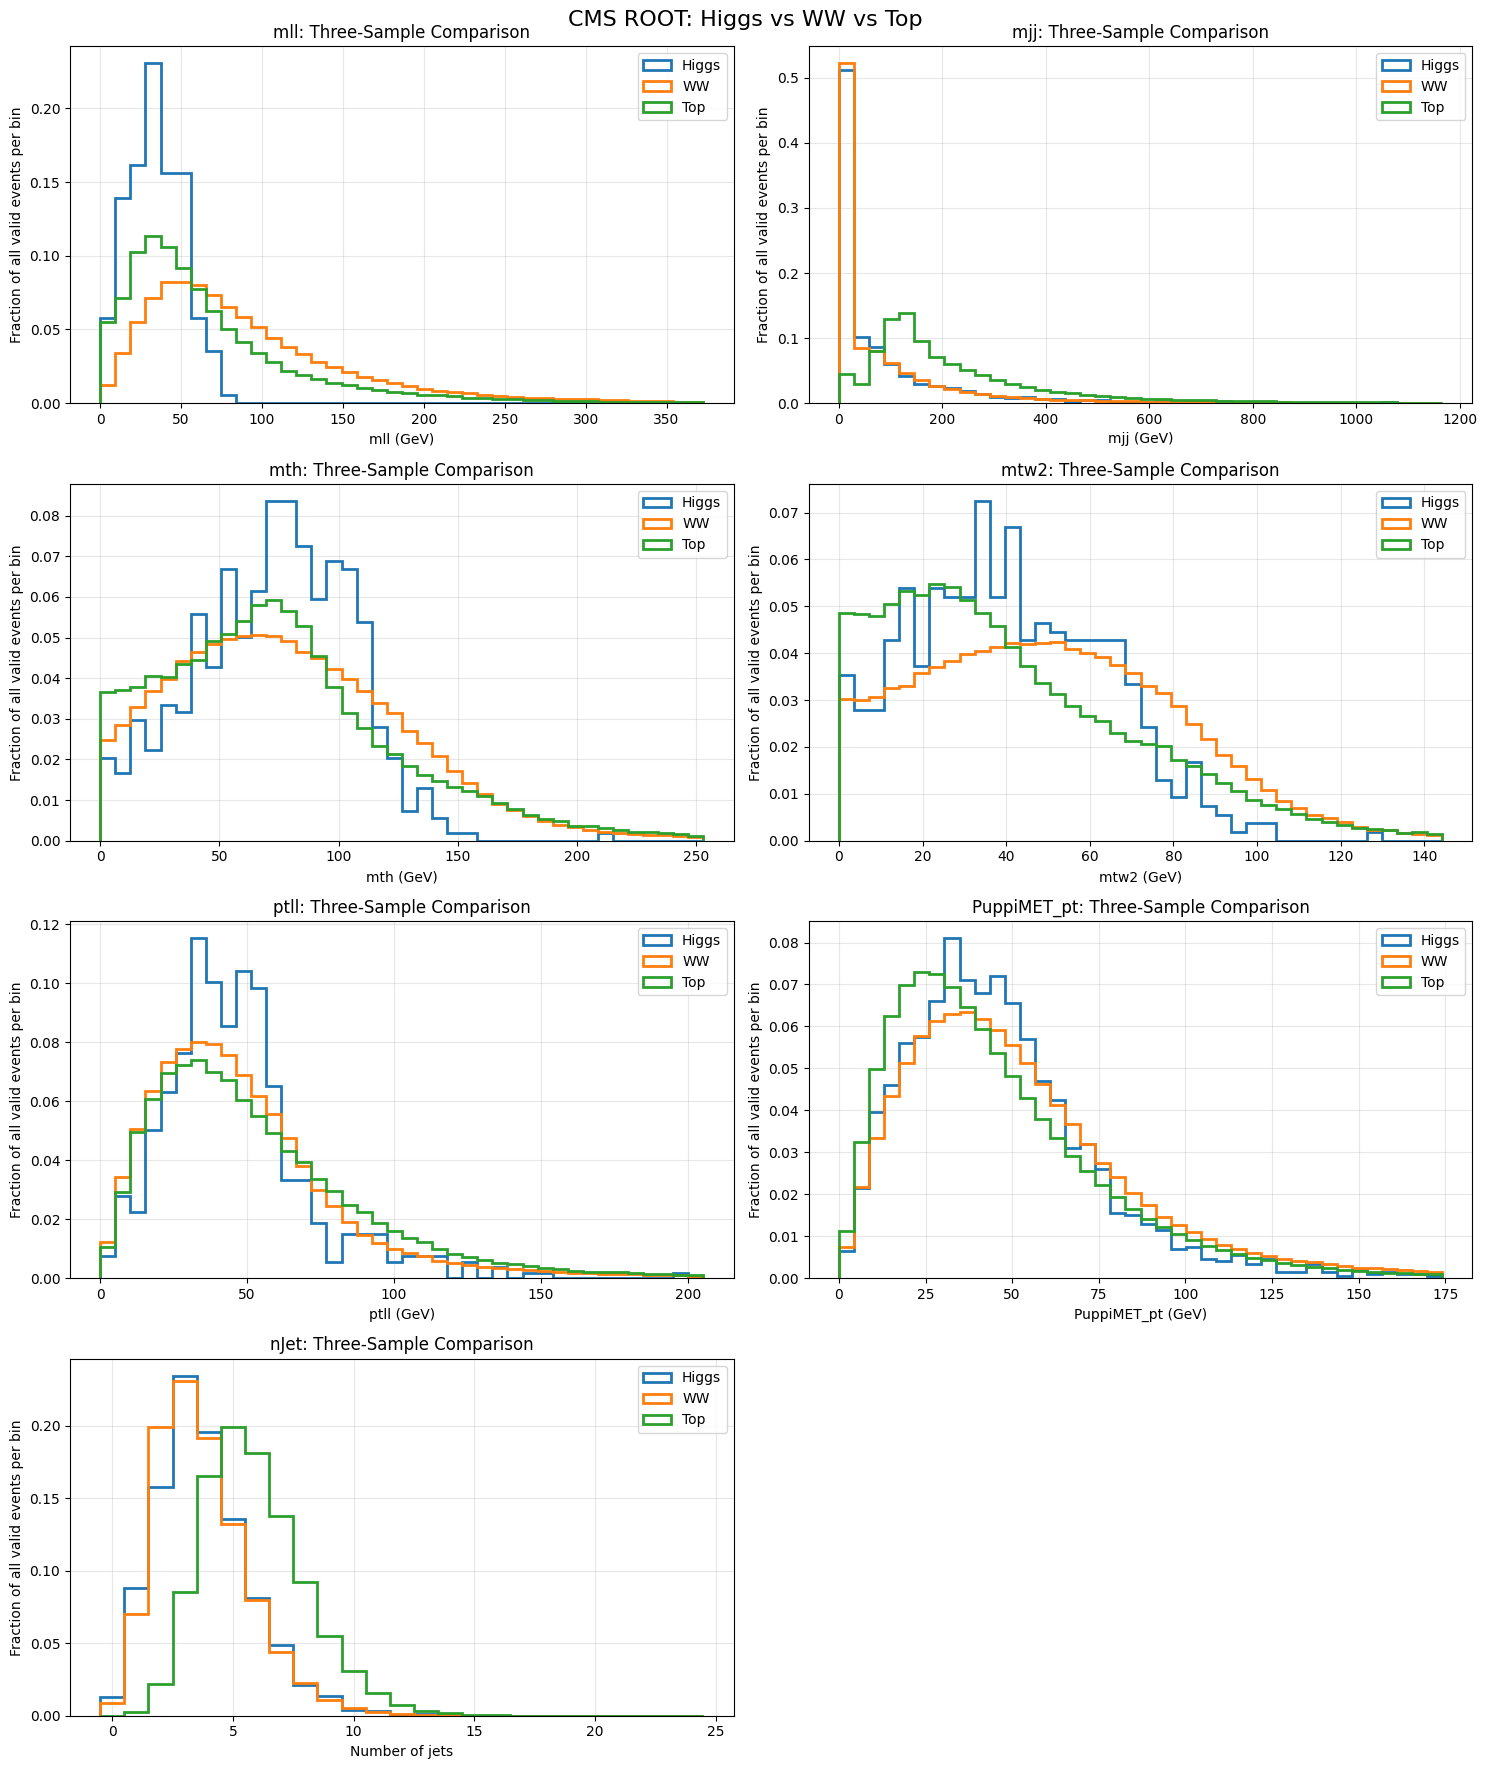


All seven graphs have been generated and saved.


In [50]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
import os

# All three datasets
samples = {
    "Higgs": "/content/Higgs.root",
    "WW": "/content/WW-train.root",
    "Top": "/content/Top-train.root"
}

# Check that all files exist
for name, path in samples.items():
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Cannot find {path}. Check the uploaded filename."
        )

# Variables to compare
variables = [
    "mll",
    "mjj",
    "mth",
    "mtw2",
    "ptll",
    "PuppiMET_pt",
    "nJet"
]

# Read a variable from the ROOT file
def read_variable(filepath, variable):
    with uproot.open(filepath) as root_file:
        for key in root_file.keys():
            obj = root_file[key]

            if (hasattr(obj, "num_entries")
                    and variable in obj.keys()):

                values = obj[variable].array(library="np")
                values = np.asarray(values, dtype=float)

                # Remove invalid values and negative placeholders
                values = values[np.isfinite(values)]
                values = values[values >= 0]

                return values

    raise ValueError(
        f"Variable '{variable}' not found in {filepath}"
    )

# Create seven comparison graphs
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for i, variable in enumerate(variables):
    ax = axes[i]
    data = {}

    # Read the same variable from each dataset
    for name, path in samples.items():
        data[name] = read_variable(path, variable)

    # Ensure there is data to plot
    nonempty = [v for v in data.values() if len(v) > 0]

    if not nonempty:
        ax.set_title(f"{variable}: No valid data")
        continue

    combined = np.concatenate(nonempty)

    # Use common bins for a fair comparison
    if variable == "nJet":
        max_value = int(np.max(combined))
        bins = np.arange(-0.5, max_value + 1.5, 1)
    else:
        # Zoom in on the main distribution.
        # Values beyond this range are reported below.
        upper = np.percentile(combined, 99)
        upper = max(upper, 0.001)
        bins = np.linspace(0, upper, 41)

    print(f"\nVariable: {variable}")

    # Overlay the three histograms
    for name, values in data.items():

        if len(values) == 0:
            print(f"{name}: No valid values")
            continue

        if variable == "nJet":
            visible = values
        else:
            visible = values[values <= bins[-1]]
            outside = np.sum(values > bins[-1])

            print(
                f"{name}: {outside} values outside "
                f"the displayed range"
            )

        # Weights keep different sample sizes comparable.
        # Fractions are calculated relative to all valid events.
        weights = np.ones(len(visible)) / len(values)

        ax.hist(
            visible,
            bins=bins,
            weights=weights,
            histtype="step",
            linewidth=2,
            label=name
        )

    ax.set_title(f"{variable}: Three-Sample Comparison")
    ax.set_xlabel(
        "Number of jets" if variable == "nJet"
        else f"{variable} (GeV)"
    )
    ax.set_ylabel("Fraction of all valid events per bin")
    ax.legend()
    ax.grid(alpha=0.3)

# Remove the unused eighth panel
fig.delaxes(axes[-1])

fig.suptitle(
    "CMS ROOT: Higgs vs WW vs Top",
    fontsize=16
)

plt.tight_layout()

# Save the results
plt.savefig(
    "/content/three_sample_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nAll seven graphs have been generated and saved.")